<a href="https://colab.research.google.com/github/Hassanat718/Module-2_Case-Exercise-1-Design-Envelope-Construction-and-Visualisation-/blob/hassanah/Module2_Case_Exercise_2_Corrosion_Rate_Prediction_and_Remaining_Life.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
!git clone https://{token}@github.com/{username}/{repo}

Cloning into 'Module-2_Case-Exercise-1-Design-Envelope-Construction-and-Visualisation-'...
remote: Enumerating objects: 12, done.
remote: Counting objects: 100% (12/12), done.
remote: Compressing objects: 100% (10/10), done.
remote: Total 12 (delta 3), reused 6 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (12/12), 22.08 MiB | 22.86 MiB/s, done.
Resolving deltas: 100% (3/3), done.


# **QUESTION 1**
Implement the de Waard-Milliams corrosion rate model with unit tests.

In [ ]:
import math


def de_waard_milliams_corrosion_rate(
    temperature_c: float,
    co2_partial_pressure_bar: float,
    ph: float = 4.5
) -> float:
    """
    Estimate CO2 corrosion rate using the supplied simplified
    de Waard–Milliams formulation.

    Parameters
    ----------
    temperature_c : float
        Operating temperature in degrees Celsius.
    co2_partial_pressure_bar : float
        CO2 partial pressure in bar; must be positive.
    ph : float
        Water pH. Defaults to 4.5.

    Returns
    -------
    float
        Estimated corrosion rate in mm/year, rounded to 3 decimals.
    """
    values = [temperature_c, co2_partial_pressure_bar, ph]

    if not all(math.isfinite(v) for v in values):
        raise ValueError("All inputs must be finite numbers.")

    if temperature_c <= -273.15:
        raise ValueError("Temperature must be above absolute zero.")

    if co2_partial_pressure_bar <= 0:
        raise ValueError("CO2 partial pressure must be positive.")

    if not 0 <= ph <= 14:
        raise ValueError("pH must be between 0 and 14.")

    # Temperature and CO2 partial-pressure relationship
    log_cr = (
        5.8
        - 1710 / (temperature_c + 273.15)
        + 0.67 * math.log10(co2_partial_pressure_bar)
    )

    cr_mm_yr = 10 ** log_cr

    # Apply the supplied pH correction above pH 4.5
    if ph > 4.5:
        cr_mm_yr *= 10 ** (-0.32 * (ph - 4.5))

    return round(cr_mm_yr, 3)

# **Test the example supplied in your course**

In [ ]:

cr = de_waard_milliams_corrosion_rate(
    temperature_c=60,
    co2_partial_pressure_bar=2.5
)

print(f"Estimated corrosion rate: {cr} mm/yr")

Estimated corrosion rate: 8.586 mm/yr


# **Writing the unit tests**

In [6]:
import pytest

def test_reference_example():
    result = de_waard_milliams_corrosion_rate(60, 2.5)
    assert result == round(
        10 ** (
            5.8
            - 1710 / (60 + 273.15)
            + 0.67 * math.log10(2.5)
        ),
        3
    )


def test_default_ph_matches_ph_4_5():
    default_result = de_waard_milliams_corrosion_rate(60, 2.5)
    explicit_result = de_waard_milliams_corrosion_rate(60, 2.5, 4.5)
    assert default_result == explicit_result


def test_higher_ph_reduces_rate():
    low_ph_rate = de_waard_milliams_corrosion_rate(60, 2.5, 4.5)
    high_ph_rate = de_waard_milliams_corrosion_rate(60, 2.5, 6.0)
    assert high_ph_rate < low_ph_rate


def test_higher_co2_pressure_increases_rate():
    low_pressure = de_waard_milliams_corrosion_rate(60, 1.0)
    high_pressure = de_waard_milliams_corrosion_rate(60, 2.0)
    assert high_pressure > low_pressure


def test_invalid_co2_pressure():
    with pytest.raises(ValueError):
        de_waard_milliams_corrosion_rate(60, 0)


def test_negative_co2_pressure():
    with pytest.raises(ValueError):
        de_waard_milliams_corrosion_rate(60, -1)


def test_invalid_temperature():
    with pytest.raises(ValueError):
        de_waard_milliams_corrosion_rate(-273.15, 2.5)


def test_invalid_ph():
    with pytest.raises(ValueError):
        de_waard_milliams_corrosion_rate(60, 2.5, 15)


def test_non_finite_input():
    with pytest.raises(ValueError):
        de_waard_milliams_corrosion_rate(float("nan"), 2.5)


def test_result_is_rounded_to_three_decimals():
    result = de_waard_milliams_corrosion_rate(60, 2.5)
    assert result == round(result, 3)

# **Runing the tests**

In [7]:

pytest.main(["-v", "--tb=short"])


============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: typeguard-4.6.0, anyio-4.15.1, langsmith-0.14.11, platformdirs-4.13.4
collecting ... collected 0 items

============================ no tests ran in 0.01s =============================


<ExitCode.NO_TESTS_COLLECTED: 5>

# **QUESTION 2**
Generate a synthetic 10-year SCADA dataset (hourly readings) with realistic parameter ranges for the Usan field.

In [8]:

import numpy as np
import pandas as pd
from pathlib import Path

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

timestamps = pd.date_range(
    start="2016-01-01 00:00:00",
    end="2025-12-31 23:00:00",
    freq="h"
)

assets = [
    "SUBSEA_01", "SUBSEA_02", "SUBSEA_03", "SUBSEA_04",
    "SUBSEA_05", "SUBSEA_06", "SUBSEA_07", "SUBSEA_08"
]

print("Hourly timestamps:", len(timestamps))
print("Assets:", len(assets))
print("Expected total rows:", len(timestamps) * len(assets))


Hourly timestamps: 87672
Assets: 8
Expected total rows: 701376


# **Define the reference operating conditions**

In [10]:

asset_conditions = pd.DataFrame({
    "asset_id": assets,
    "base_pressure_psi": [
        4200, 4400, 3800, 3200, 4467, 4100, 3900, 4300
    ],
    "base_temperature_c": [
        65, 72, 58, 55, 78, 68, 63, 74
    ],
    "base_water_cut_pct": [
        32, 45, 28, 38, 62, 40, 35, 55
    ],
    "base_co2_partial_pressure_bar": [
        0.8, 1.2, 0.6, 0.7, 1.8, 1.0, 0.9, 1.5
    ],
    "base_ph": [
        5.0, 4.7, 5.3, 5.1, 4.4, 4.8, 5.0, 4.6
    ],
    "base_flow_m3_day": [
        1800, 1600, 2100, 1200, 1400, 1900, 1750, 1500
    ]
})

asset_conditions

,asset_id,base_pressure_psi,base_temperature_c,base_water_cut_pct,base_co2_partial_pressure_bar,base_ph,base_flow_m3_day
0,SUBSEA_01,4200,65,32,0.8,5.0,1800
1,SUBSEA_02,4400,72,45,1.2,4.7,1600
2,SUBSEA_03,3800,58,28,0.6,5.3,2100
3,SUBSEA_04,3200,55,38,0.7,5.1,1200
4,SUBSEA_05,4467,78,62,1.8,4.4,1400
5,SUBSEA_06,4100,68,40,1.0,4.8,1900
6,SUBSEA_07,3900,63,35,0.9,5.0,1750
7,SUBSEA_08,4300,74,55,1.5,4.6,1500


# **Generate the synthetic hourly readings**

In [11]:

frames = []

hour_of_day = timestamps.hour.to_numpy()
day_index = np.arange(len(timestamps)) / 24

daily_cycle = np.sin(2 * np.pi * hour_of_day / 24)
slow_cycle = np.sin(2 * np.pi * day_index / 90)

for row in asset_conditions.itertuples(index=False):
    n = len(timestamps)

    pressure = (
        row.base_pressure_psi
        + 35 * daily_cycle
        + 25 * slow_cycle
        + rng.normal(0, 18, n)
    )

    temperature = (
        row.base_temperature_c
        + 1.5 * daily_cycle
        + 1.0 * slow_cycle
        + rng.normal(0, 0.6, n)
    )

    water_cut = (
        row.base_water_cut_pct
        + 2.0 * slow_cycle
        + rng.normal(0, 0.8, n)
    )

    co2_pressure = (
        row.base_co2_partial_pressure_bar
        + 0.06 * daily_cycle
        + rng.normal(0, 0.04, n)
    )

    ph = (
        row.base_ph
        + 0.05 * slow_cycle
        + rng.normal(0, 0.03, n)
    )

    flow_rate = (
        row.base_flow_m3_day
        + 0.03 * row.base_flow_m3_day * daily_cycle
        + rng.normal(0, 0.02 * row.base_flow_m3_day, n)
    )

    # Apply the synthetic operating ranges
    pressure = np.clip(pressure, 2800, 4700)
    temperature = np.clip(temperature, 45, 85)
    water_cut = np.clip(water_cut, 10, 80)
    co2_pressure = np.clip(co2_pressure, 0.1, 2.5)
    ph = np.clip(ph, 3.8, 6.5)
    flow_rate = np.clip(flow_rate, 0, 3000)

    # Simulate occasional low-operation periods
    shutdown = rng.random(n) < 0.002
    flow_rate[shutdown] = 0

    frames.append(pd.DataFrame({
        "timestamp": timestamps,
        "asset_id": row.asset_id,
        "operating_pressure_psi": pressure.round(2),
        "operating_temperature_c": temperature.round(2),
        "water_cut_pct": water_cut.round(2),
        "co2_partial_pressure_bar": co2_pressure.round(4),
        "ph": ph.round(3),
        "flow_rate_m3_day": flow_rate.round(2),
        "shutdown_flag": shutdown,
        "data_source": "synthetic"
    }))

scada_df = pd.concat(frames, ignore_index=True)

print("Dataset shape:", scada_df.shape)
scada_df.head()


Dataset shape: (701376, 10)


,timestamp,asset_id,operating_pressure_psi,operating_temperature_c,water_cut_pct,co2_partial_pressure_bar,ph,flow_rate_m3_day,shutdown_flag,data_source
0,2016-01-01 00:00:00,SUBSEA_01,4205.48,64.39,31.43,0.8266,4.968,1769.15,False,synthetic
1,2016-01-01 01:00:00,SUBSEA_01,4190.41,65.27,32.91,0.8723,4.961,1764.23,False,synthetic
2,2016-01-01 02:00:00,SUBSEA_01,4231.15,66.17,31.00,0.8534,5.016,1845.17,False,synthetic
3,2016-01-01 03:00:00,SUBSEA_01,4241.90,65.90,32.23,0.8183,5.035,1805.83,False,synthetic
4,2016-01-01 04:00:00,SUBSEA_01,4195.48,67.02,33.13,0.8534,5.025,1867.85,False,synthetic


# **Validate the dataset**

In [12]:

assert len(scada_df) == 701_376
assert scada_df["asset_id"].nunique() == 8
assert scada_df["timestamp"].nunique() == 87_672
assert scada_df.isna().sum().sum() == 0
assert not scada_df.duplicated(["timestamp", "asset_id"]).any()

assert scada_df["operating_pressure_psi"].between(2800, 4700).all()
assert scada_df["operating_temperature_c"].between(45, 85).all()
assert scada_df["water_cut_pct"].between(10, 80).all()
assert scada_df["co2_partial_pressure_bar"].gt(0).all()
assert scada_df["ph"].between(3.8, 6.5).all()
assert scada_df["flow_rate_m3_day"].ge(0).all()

print("All validation checks passed.")
print("Missing values:", scada_df.isna().sum().sum())
print("Duplicate timestamp-asset rows:",
      scada_df.duplicated(["timestamp", "asset_id"]).sum())

All validation checks passed.
Missing values: 0
Duplicate timestamp-asset rows: 0


In [ ]:
output_dir = Path("data")
output_dir.mkdir(parents=True, exist_ok=True)

csv_path = output_dir / "usan_synthetic_scada_10yr.csv"
scada_df.to_csv(csv_path, index=False)

print(f"CSV saved to: {csv_path.resolve()}")


CSV saved to: /content/data/usan_synthetic_scada_10yr.csv


# **Summarize the generated data**

In [13]:
summary = scada_df.groupby("asset_id").agg(
    mean_pressure_psi=("operating_pressure_psi", "mean"),
    mean_temperature_c=("operating_temperature_c", "mean"),
    mean_water_cut_pct=("water_cut_pct", "mean"),
    mean_co2_pressure_bar=("co2_partial_pressure_bar", "mean"),
    mean_ph=("ph", "mean"),
    mean_flow_m3_day=("flow_rate_m3_day", "mean"),
    shutdown_hours=("shutdown_flag", "sum")
).round(2)

summary


,mean_pressure_psi,mean_temperature_c,mean_water_cut_pct,mean_co2_pressure_bar,mean_ph,mean_flow_m3_day,shutdown_hours
asset_id,,,,,,,
SUBSEA_01,4200.14,65.01,32.02,0.8,5.0,1795.93,200
SUBSEA_02,4400.15,72.01,45.01,1.2,4.7,1597.11,166
SUBSEA_03,3800.31,58.01,28.01,0.6,5.3,2096.19,165
SUBSEA_04,3200.13,55.01,38.02,0.7,5.1,1197.50,182
SUBSEA_05,4467.17,78.01,62.02,1.8,4.4,1397.02,189
SUBSEA_06,4100.36,68.01,40.01,1.0,4.8,1896.07,184
SUBSEA_07,3900.24,63.00,35.01,0.9,5.0,1746.87,161
SUBSEA_08,4300.23,74.01,55.02,1.5,4.6,1497.10,174


# **Apply the PhysicsFeaturePipeline to the synthetic data and compute monthly average corrosion rates.**

In [14]:

class PhysicsFeaturePipeline:
    """
    Add physics-derived corrosion features to SCADA data.

    Requires:
        operating_temperature_c
        co2_partial_pressure_bar
        ph
    """

    def transform(self, df):
        required_columns = [
            "operating_temperature_c",
            "co2_partial_pressure_bar",
            "ph"
        ]

        missing = set(required_columns) - set(df.columns)
        if missing:
            raise ValueError(f"Missing required columns: {sorted(missing)}")

        result = df.copy()

        result["predicted_corrosion_rate_mm_yr"] = [
            de_waard_milliams_corrosion_rate(
                temperature_c=temp,
                co2_partial_pressure_bar=co2,
                ph=ph
            )
            for temp, co2, ph in zip(
                result["operating_temperature_c"],
                result["co2_partial_pressure_bar"],
                result["ph"]
            )
        ]

        return result


# **Apply the pipeline**

In [15]:
pipeline = PhysicsFeaturePipeline()

enriched_df = pipeline.transform(scada_df)

print("Original dataset shape:", scada_df.shape)
print("Enriched dataset shape:", enriched_df.shape)

enriched_df[
    [
        "timestamp",
        "asset_id",
        "operating_temperature_c",
        "co2_partial_pressure_bar",
        "ph",
        "predicted_corrosion_rate_mm_yr"
    ]
].head()

Original dataset shape: (701376, 10)
Enriched dataset shape: (701376, 11)


,timestamp,asset_id,operating_temperature_c,co2_partial_pressure_bar,ph,predicted_corrosion_rate_mm_yr
0,2016-01-01 00:00:00,SUBSEA_01,64.39,0.8266,4.968,3.379
1,2016-01-01 01:00:00,SUBSEA_01,65.27,0.8723,4.961,3.629
2,2016-01-01 02:00:00,SUBSEA_01,66.17,0.8534,5.016,3.542
3,2016-01-01 03:00:00,SUBSEA_01,65.90,0.8183,5.035,3.365
4,2016-01-01 04:00:00,SUBSEA_01,67.02,0.8534,5.025,3.622


# **Calculate monthly average corrosion rates**

In [16]:

enriched_df["month"] = (
    enriched_df["timestamp"].dt.to_period("M")
)

monthly_corrosion = (
    enriched_df
    .groupby(["asset_id", "month"], as_index=False)
    .agg(
        monthly_avg_corrosion_rate_mm_yr=(
            "predicted_corrosion_rate_mm_yr", "mean"
        ),
        monthly_max_corrosion_rate_mm_yr=(
            "predicted_corrosion_rate_mm_yr", "max"
        ),
        hourly_readings=("predicted_corrosion_rate_mm_yr", "count")
    )
)

monthly_corrosion["month"] = (
    monthly_corrosion["month"].dt.to_timestamp()
)

monthly_corrosion[
    "monthly_avg_corrosion_rate_mm_yr"
] = monthly_corrosion[
    "monthly_avg_corrosion_rate_mm_yr"
].round(3)

monthly_corrosion[
    "monthly_max_corrosion_rate_mm_yr"
] = monthly_corrosion[
    "monthly_max_corrosion_rate_mm_yr"
].round(3)

print("Monthly dataset shape:", monthly_corrosion.shape)
monthly_corrosion.head()


Monthly dataset shape: (960, 5)


,asset_id,month,monthly_avg_corrosion_rate_mm_yr,monthly_max_corrosion_rate_mm_yr,hourly_readings
0,SUBSEA_01,2016-01-01,3.295,3.950,744
1,SUBSEA_01,2016-02-01,3.305,4.044,696
2,SUBSEA_01,2016-03-01,3.315,4.143,744
3,SUBSEA_01,2016-04-01,3.298,4.030,720
4,SUBSEA_01,2016-05-01,3.291,3.984,744


# **Validate the monthly results**

In [17]:

assert len(monthly_corrosion) == 960

assert not monthly_corrosion.duplicated(
    ["asset_id", "month"]
).any()

assert monthly_corrosion[
    "monthly_avg_corrosion_rate_mm_yr"
].notna().all()

assert (
    monthly_corrosion["monthly_avg_corrosion_rate_mm_yr"] >= 0
).all()

assert monthly_corrosion["hourly_readings"].between(
    672, 744
).all()

print("Monthly aggregation validation passed.")
print(
    "Minimum monthly average:",
    monthly_corrosion[
        "monthly_avg_corrosion_rate_mm_yr"
    ].min(),
    "mm/yr"
)
print(
    "Maximum monthly average:",
    monthly_corrosion[
        "monthly_avg_corrosion_rate_mm_yr"
    ].max(),
    "mm/yr"
)

Monthly aggregation validation passed.
Minimum monthly average: 1.7 mm/yr
Maximum monthly average: 12.997 mm/yr


# **Visualise monthly corrosion trends**

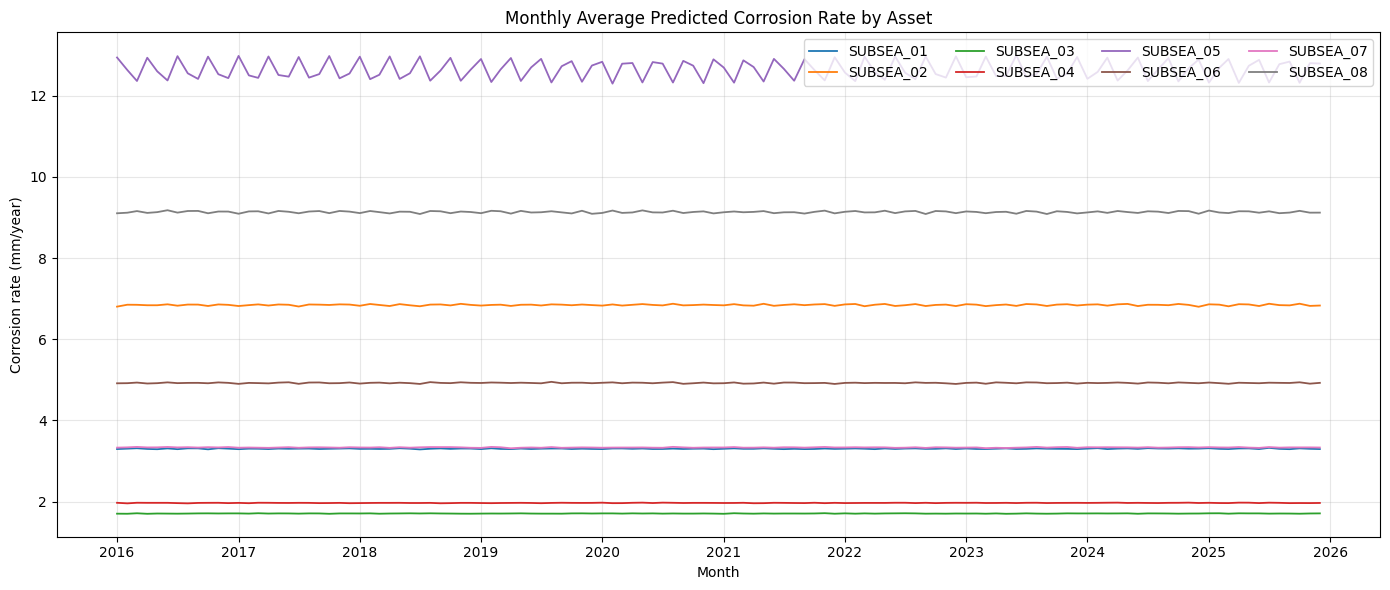

In [18]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

for asset in assets:
    asset_data = monthly_corrosion[
        monthly_corrosion["asset_id"] == asset
    ]

    plt.plot(
        asset_data["month"],
        asset_data["monthly_avg_corrosion_rate_mm_yr"],
        label=asset,
        linewidth=1.3
    )

plt.title("Monthly Average Predicted Corrosion Rate by Asset")
plt.xlabel("Month")
plt.ylabel("Corrosion rate (mm/year)")
plt.legend(ncol=4)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [22]:
%ls

Module_2_Case_Exercise_1_Design_Envelope_Construction_and_Visualisation.ipynb
README.md
usan_monthly_corrosion_rates.csv
usan_synthetic_scada_10yr.csv
usan_synthetic_scada_enriched.csv


In [21]:
%cd /content/Module-2_Case-Exercise-1-Design-Envelope-Construction-and-Visualisation-

/content/Module-2_Case-Exercise-1-Design-Envelope-Construction-and-Visualisation-


In [ ]:
!mv /content/Module2_Case_Exercise_2_Corrosion_Rate_Prediction_and_Remaining_Life.ipynb /content/Module-2_Case-Exercise-1-Design-Envelope-Construction-and-Visualisation-

In [24]:
!git status

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [25]:
!git add --all

In [26]:
!git commit -m "Complete Case Exercise 2: Corrosion Rate Prediction and Remaining Life"

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [27]:
!git remote

origin


In [ ]:
!git push origin main

Enumerating objects: 6, done.
Counting objects: 100% (6/6), done.
Delta compression using up to 2 threads
Compressing objects: 100% (5/5), done.
Writing objects: 100% (5/5), 21.88 MiB | 2.05 MiB/s, done.
Total 5 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1), done.
remote: warning: See https://gh.io/lfs for more information.
remote: warning: File usan_synthetic_scada_10yr.csv is 57.77 MB; this is larger than GitHub's recommended maximum file size of 50.00 MB
remote: warning: File usan_synthetic_scada_enriched.csv is 67.15 MB; this is larger than GitHub's recommended maximum file size of 50.00 MB
remote: warning: GH001: Large files detected. You may want to try Git Large File Storage - https://git-lfs.github.com.
To https://github.com/Hassanat718/Module-2_Case-Exercise-1-Design-Envelope-Construction-and-Visualisation-
   6ec918c..046aef1  main -> main


In [ ]:
!git checkout -b hassanah

Switched to a new branch 'hassanah'


In [ ]:
!git push origin hassanah

Enumerating objects: 4, done.
Counting objects: 100% (4/4), done.
Delta compression using up to 2 threads
Compressing objects: 100% (3/3), done.
Writing objects: 100% (3/3), 128.25 KiB | 8.55 MiB/s, done.
Total 3 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1), completed with 1 local object.
remote: error: GH013: Repository rule violations found for refs/heads/hassanah.
remote: 
remote: - GITHUB PUSH PROTECTION
remote:   —————————————————————————————————————————
remote:     Resolve the following violations before pushing again
remote: 
remote:     - Push cannot contain secrets
remote: 
remote:     
remote:      (?) Learn how to resolve a blocked push
remote:      https://docs.github.com/code-security/secret-scanning/working-with-secret-scanning-and-push-protection/working-with-push-protection-from-the-command-line#resolving-a-blocked-push
remote:     
remote:     
remote:       —— GitHub Personal Access Token ——————————————————————
remote:        locat

# **QUESTION 4**
Calculate remaining useful life for each of the 6 jumpers from the case study. Create a visualisation showing RUL vs. corrosion rate with a colour-coded risk classification    

# **Formula**

The Remaining Useful Life (RUL) is calculated using the following formula:

$$
\text{RUL} = \frac{t_{\text{current}} - t_{\text{minimum}}}{CR}
$$

Where:

$t_{\text{current}}$ = current measured wall thickness (mm).

$t_{\text{minimum}}$ = minimum allowable wall thickness (mm), assumed to be 8.5 mm for this exercise.

$CR$ = corrosion rate (mm/year).

Example:

If a jumper has a current wall thickness of 11.2 mm and a corrosion rate of 0.15 mm/year:

$$
\text{RUL} = \frac{11.2 - 8.5}{0.15}
$$

$$
\text{RUL} = \frac{2.7}{0.15} = 18 \text{ years}
$$

Therefore, the estimated remaining useful life of the jumper is 18 years, assuming the corrosion rate remains constant.

In [28]:

import pandas as pd
import matplotlib.pyplot as plt

# Synthetic jumper inspection data
data = {
    "Jumper_ID": ["J-001", "J-002", "J-003",
                  "J-004", "J-005", "J-006"],
    "Current_WT_mm": [11.2, 10.8, 11.5, 8.9, 10.1, 11.0],
    "Corrosion_Rate_mm_yr": [0.15, 0.19, 0.12, 0.14, 0.26, 0.17]
}

df = pd.DataFrame(data)

# Assumed minimum allowable wall thickness
minimum_wt = 8.5

# Calculate remaining useful life
df["RUL_years"] = (
    (df["Current_WT_mm"] - minimum_wt)
    / df["Corrosion_Rate_mm_yr"]
)

# Classify corrosion risk using the agreed thresholds
def classify_risk(rate):
    if rate < 0.05:
        return "Negligible"
    elif rate < 0.13:
        return "Low"
    elif rate < 0.25:
        return "Medium"
    elif rate <= 0.50:
        return "High"
    else:
        return "Severe"

df["Risk_Class"] = df["Corrosion_Rate_mm_yr"].apply(
    classify_risk
)

# Display results
df["RUL_years"] = df["RUL_years"].round(2)

print(df.to_string(index=False))


Jumper_ID  Current_WT_mm  Corrosion_Rate_mm_yr  RUL_years Risk_Class
    J-001           11.2                  0.15      18.00     Medium
    J-002           10.8                  0.19      12.11     Medium
    J-003           11.5                  0.12      25.00        Low
    J-004            8.9                  0.14       2.86     Medium
    J-005           10.1                  0.26       6.15       High
    J-006           11.0                  0.17      14.71     Medium


# **Visualize RUL against corrosion rate**

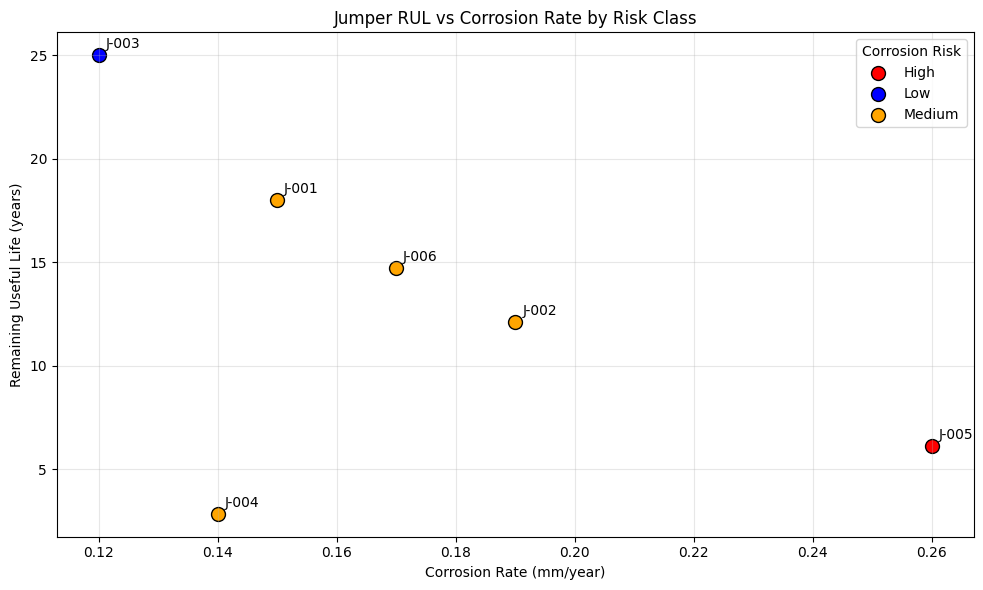

In [29]:

# Map risk classes to plot colours
risk_colours = {
    "Negligible": "green",
    "Low": "blue",
    "Medium": "orange",
    "High": "red",
    "Severe": "purple"
}

plt.figure(figsize=(10, 6))

for risk, group in df.groupby("Risk_Class"):
    plt.scatter(
        group["Corrosion_Rate_mm_yr"],
        group["RUL_years"],
        color=risk_colours[risk],
        label=risk,
        s=100,
        edgecolor="black"
    )

    # Label each point with its jumper ID
    for _, row in group.iterrows():
        plt.annotate(
            row["Jumper_ID"],
            (row["Corrosion_Rate_mm_yr"], row["RUL_years"]),
            xytext=(5, 5),
            textcoords="offset points"
        )

plt.xlabel("Corrosion Rate (mm/year)")
plt.ylabel("Remaining Useful Life (years)")
plt.title("Jumper RUL vs Corrosion Rate by Risk Class")
plt.legend(title="Corrosion Risk")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# **Engineering interpretation**
- J-004 requires the closest attention: its estimated RUL is only 2.86 years, and its current wall thickness of 8.9 mm is close to the assumed 8.5 mm minimum.
- J-005 has the highest corrosion rate: 0.26 mm/year, placing it in the high-risk category, with an estimated RUL of 6.15 years.
- J-003 has the longest estimated RUL: 25 years, with the lowest corrosion rate among these six jumpers.